# v9 - Directo de Tokio (rio Myoshoji): el STIV como programa en tiempo real

Convierte el STIV de la v8 en un **motor que mide mientras llega el video**: las camaras de
vigilancia de rios del Gobierno Metropolitano de Tokio emiten en directo por YouTube, y el programa
de `casos/09_directo_tokio` mide la velocidad superficial **cada segundo** sobre los ultimos 10 s, en
un PC o en una Raspberry Pi. Aqui se ejecuta sobre el **video de prueba de 20 s** del rio Myoshoji
que viaja con el programa (`raspberry/prueba/myoshoji_20s.mp4`), leido fotograma a fotograma como si
fuera el directo, y al final se pasa **el mismo motor por el video crudo del Sile Main Canal**, el
caso de la v2 y la v3, contra su aforo.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera se escribe en
`salidas/`.** Las lineas de codigo que cambian respecto a la v8 llevan la marca `# [v9]`.

---
## Que cambia respecto a v8

| Parte | v8 (canal Yaqui) | v9 (directo de Tokio) | Por que lo obliga este caso |
|---|---|---|---|
| 0 | constantes sueltas para un video | **presets por fuente** (`FUENTES`): todo lo que depende de la camara | el programa cambia de camara en marcha; el metodo es uno solo |
| 1 | todos los fotogramas | solo los **fotogramas reales**: la cadencia se mide al arrancar | YouTube duplica fotogramas, y no siempre igual (cada 2 en el video de prueba, cada 3 en otra grabacion del mismo directo) |
| 2 | orillas + punto de fuga + focal supuesta | **cuadrilatero** trazado sobre la imagen con dimensiones **supuestas** (`getPerspectiveTransform`) | en estas camaras no hay dos orillas rectas que detectar; el cuadrilatero se edita en vivo |
| 3-4 | plano rectificado entero (`remap` de 1.3 Mpx por fotograma) | las lineas se muestrean **directamente en la imagen**, con antialias segun los px por muestra y solo sobre el recuadro que tocan | tiempo real en una Raspberry Pi |
| 4 | una STI de todo el video, medida una vez | **buffer** de los ultimos 10 s y **una medida por segundo** | es un directo: no hay "todo el video" |
| 4 | votan los bloques con particula (cuantil de brillo) | votan los pixeles y bloques **activos**: los que cambian entre fotogramas reales | el codec de YouTube **congela** parches de agua: estelas verticales perfectas (v = 0) con mucha coherencia y brillo normal; la seleccion por brillo no las distingue |
| 4 | top-hat y estabilizacion | sin realce (opcion del preset) y **sin estabilizacion** | camaras fijas, de dia; el Sile sin estabilizar lo comprueba en la Parte 7 |
| 4b | coherencia, densidad de trazador | coherencia y **bloques activos >= 6** (`sin textura`) | el agua congelada no deja bloques activos |
| 6 | coste de una pasada | **ms por fotograma y por medida**, frente al presupuesto del tiempo real | el motor tiene que ir por delante del video |
| 7 | sin referencia | contexto del caudal oficial y **regresion sobre el Sile** (v3) contra el aforo ADV | el directo no tiene aforo; el Sile si |

**Lo que no cambia:** `mapa_lineas` y `mapa_banda` (ahora en metros del cuadrilatero), la banda
normalizada y promediada, `preparar_sti`, el tensor con diferencias centrales y `SIGMA_DERIVADA` = 1.5,
`LADO_BLOQUE` = 64, `COH_MIN_BLOQUE` = 0.50, `COH_MIN_ESTACION` = 0.60, `DS` = desplazamiento por
fila, la cobertura por muestra y el modulo `benchmark`.

---
## Parte 0 - Rutas de trabajo y presets

Todo lo que depende de la camara va en un **preset**; el metodo (bloques, coherencia, actividad,
ventana) es comun. El de Myoshoji es el del programa (`CAMARAS["myoshoji"]` en `stiv_directo.py`);
el del Sile reproduce la geometria de la v3 (filas 438/1463, columnas 600-3400, flujo a -1 grado,
11 verticales cada 6 in) en forma de cuadrilatero.

**La escala de Myoshoji es un supuesto**: ancho 8.8 m +-0.7 medido en una ortofoto, largo 10 m sin
medir. Ver `casos/09_directo_tokio/README.md`.

In [1]:
import os
from pathlib import Path

import numpy as np

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)

# --- Entradas (nunca se modifican) ---
DIR_DIRECTO = Path("../../casos/09_directo_tokio")                                  # [v9]
DIR_USGS = Path("../../datos/USGS")                                                  # [v9]


def cuadrilatero_sile():
    """[v9] La geometria de la v3 (escala por las lineas de agua) como cuadrilatero."""
    e = 1.8288 / (1463 - 438)                    # m/px, las filas de la v3
    a = np.radians(-1.0)                         # ANGULO_FLUJO de la v3
    largo = (3400 - 600) * e                     # columnas 600-3400 de la v3
    def a_imagen(x, y):
        t = x / e - 1400
        return [2000 + t * np.cos(a), 438 + y / e + t * np.sin(a)]
    return [a_imagen(0, 0), a_imagen(largo, 0), a_imagen(largo, 1.8288), a_imagen(0, 1.8288)], largo


# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Presets por fuente                                               [v9]
# ---------------------------------------------------------------------------------------
_cuad_sile, _largo_sile = cuadrilatero_sile()
FUENTES = {
    # Rio Myoshoji en Kamitakada (Nakano), directo https://www.youtube.com/watch?v=huAp4q7lxiQ.
    # El agua se aleja de la camara; el cuadrilatero se traza sobre el borde del agua.
    "myoshoji": dict(video=DIR_DIRECTO / "raspberry" / "prueba" / "myoshoji_20s.mp4",
                     cuadrilatero=[[360, 700], [360, 385], [697, 385], [1010, 700]],
                     largo_m=10.0, ancho_m=8.8,          # SUPUESTOS (ancho de ortofoto, +-0.7)
                     n_estaciones=9, margen_orilla=0.06, largo_linea_m=9.0, centro_linea=0.5,
                     ancho_banda_m=0.60, lineas_banda=7, v_esperada=0.30, realce=None),
    # Sile Main Canal, video ORIGINAL sin estabilizar (el programa en directo no estabiliza).
    "sile": dict(video=DIR_USGS / "Video" / "SMC_D_RC_022_08172020_AC.mp4",
                 cuadrilatero=_cuad_sile, largo_m=_largo_sile, ancho_m=1.8288,
                 n_estaciones=11, margen_orilla=1 / 12, largo_linea_m=_largo_sile, centro_linea=0.5,
                 ancho_banda_m=0.04, lineas_banda=7, v_esperada=0.95, realce=None),
}
FUENTE = "myoshoji"
# ---------------------------------------------------------------------------------------
ARCHIVO_VIDEO = FUENTES[FUENTE]["video"]

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config.json"                 # configuracion congelada
SALIDA_SERIE = DIR_SALIDA / "medidas_directo.csv"          # [v9] una fila por estacion y medida
SALIDA_RESUMEN = DIR_SALIDA / "resumen.csv"                # tabla final
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"   # coste de cada etapa

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada.
for nombre, p in FUENTES.items():                                                    # [v9]
    print(f"  {'OK   ' if p['video'].exists() else 'FALTA'} [{nombre}] {p['video'].name}")

Salidas en:       salidas
  OK    [myoshoji] myoshoji_20s.mp4
  OK    [sile] SMC_D_RC_022_08172020_AC.mp4


---
## Parte 1 - Lectura del video, y los fotogramas que de verdad son nuevos

El directo de YouTube emite a 30 fps, pero la camara no: YouTube **repite** fotogramas. Si se
apilaran todos, la STI seria una escalera, y en cuanto el agua avanza mas de ~1.5 muestras por fila
el tensor la lee mal (con duplicados, una STI sintetica de pendiente 2.5 da 3.15: +26 %).

El programa original fijaba la cadencia por camara (15 fps, un duplicado de cada fotograma). Medido
aqui, **no es estable**: el video de prueba repite cada fotograma 2 veces, pero la grabacion de 60 s
del mismo directo (`validacion/grabaciones/myoshoji.avi`) los repite 3. Por eso la cadencia se
**mide al arrancar**: la diferencia media entre fotogramas consecutivos es 0 en los repetidos, y el
intervalo mas frecuente entre cambios es la cadencia real. Despues solo entra en la STI el fotograma
que cambia.

Dimensiones del fotograma: (720, 1280, 3)
FPS del video: 30.0000
Fotogramas en el video: 600


Cadencia real: un fotograma nuevo cada 2 -> 15.0 fps reales, DT = 66.7 ms


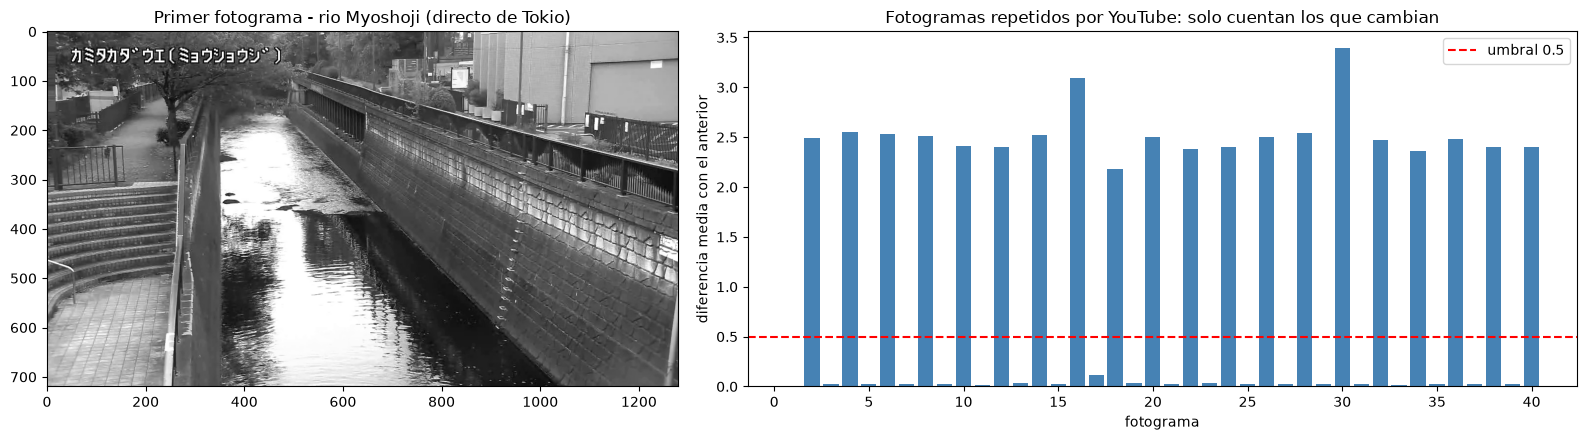

In [2]:
import cv2
import matplotlib.pyplot as plt

# OpenCV: los metadatos y el primer fotograma del video que se mide.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, frame_bgr = cap.read()
cap.release()
# OpenCV lee en BGR; matplotlib espera RGB.
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {FPS:.4f}")
print(f"Fotogramas en el video: {N_TOTAL}")

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Deteccion de fotogramas nuevos                                   [v9]
# ---------------------------------------------------------------------------------------
# Diferencia media minima (niveles de gris, sobre la imagen reducida 4x) para que un fotograma
# cuente como nuevo. Los repetidos dan 0.0-0.1; los nuevos 3-4.
UMBRAL_CAMBIO = 0.5
# ---------------------------------------------------------------------------------------


def diferencia(gris, previo):
    """[v9] Diferencia media entre dos fotogramas, sobre la imagen reducida 4x."""
    return float(np.abs(gris[::4, ::4].astype(np.float32) - previo[::4, ::4]).mean())


def cadencia_real(archivo, n=150):
    """[v9] Fotogramas del video por fotograma real: el intervalo mas frecuente entre cambios."""
    cap = cv2.VideoCapture(str(archivo))
    previo, cambios, difs = None, [], []
    for i in range(n):
        ok, fr = cap.read()
        if not ok:
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
        d = np.inf if previo is None else diferencia(gris, previo)
        difs.append(d)
        if d > UMBRAL_CAMBIO:
            cambios.append(i)
        previo = gris
    cap.release()
    intervalos = np.diff(cambios)
    k = int(np.bincount(intervalos).argmax()) if len(intervalos) else 1
    return k, np.array(difs[1:])


K_REAL, difs = cadencia_real(ARCHIVO_VIDEO)
DT = K_REAL / FPS                    # [v9] intervalo entre fotogramas REALES: entra en la velocidad
print(f"Cadencia real: un fotograma nuevo cada {K_REAL} -> {FPS / K_REAL:.1f} fps reales, "
      f"DT = {DT * 1000:.1f} ms")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[1, 1.3]))
ax[0].imshow(frame); ax[0].set_title("Primer fotograma - rio Myoshoji (directo de Tokio)")
ax[1].bar(np.arange(1, 41), difs[:40], color="steelblue")
ax[1].axhline(UMBRAL_CAMBIO, color="r", ls="--", label=f"umbral {UMBRAL_CAMBIO}")
ax[1].set_xlabel("fotograma"); ax[1].set_ylabel("diferencia media con el anterior")
ax[1].set_title("Fotogramas repetidos por YouTube: solo cuentan los que cambian"); ax[1].legend()
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Geometria: un cuadrilatero con dimensiones supuestas

En estas camaras no hay hiladas de muro (v4) ni dos orillas rectas que detectar (v8), ni puntos de
control (v5). Lo que hace el programa en directo es lo mas general: un **cuadrilatero** trazado a mano
sobre el borde del agua, que en el programa se arrastra en vivo, y unas dimensiones `largo x ancho` en
metros que, aqui, son **supuestas**. La homografia sale de los cuatro vertices
(`getPerspectiveTransform`). Todo lo que sigue esta en metros de ese rectangulo: `x` aguas abajo,
`y` de una orilla a la otra.

La verificacion es la misma de siempre: en la vista rectificada el cauce tiene que salir recto.

In [3]:
def geometria(p):
    """[v9] Homografia mundo (m) -> imagen (px) del cuadrilatero de un preset."""
    L, W = p["largo_m"], p["ancho_m"]
    mundo = np.float32([[0, 0], [L, 0], [L, W], [0, W]])
    return cv2.getPerspectiveTransform(mundo, np.float32(p["cuadrilatero"]))


def a_imagen(H, puntos):
    """[v9] Puntos (N, 2) del mundo a pixeles de la imagen."""
    return cv2.perspectiveTransform(np.float32(puntos).reshape(-1, 1, 2), H).reshape(-1, 2)


P = FUENTES[FUENTE]
H_MUNDO = geometria(P)
ALTO_PX, ANCHO_PX = frame.shape[:2]
# Vista rectificada solo para mirar: 60 px por metro, con medio rectangulo de margen.
ESC_VISTA = 60.0
S = np.array([[ESC_VISTA, 0, 0.25 * P["largo_m"] * ESC_VISTA],
              [0, ESC_VISTA, 0.25 * P["ancho_m"] * ESC_VISTA], [0, 0, 1.0]])
vista = cv2.warpPerspective(frame_bgr, S @ np.linalg.inv(H_MUNDO),
                            (int(1.5 * P["largo_m"] * ESC_VISTA), int(1.5 * P["ancho_m"] * ESC_VISTA)))
print(f"Rectangulo SUPUESTO de {P['largo_m']} m x {P['ancho_m']} m")

Rectangulo SUPUESTO de 10.0 m x 8.8 m


---
## Parte 3 - Lineas de busqueda

Las de la v8, en metros del rectangulo: `n_estaciones` repartidas a lo ancho dejando un margen junto
a cada orilla, cada una una **banda** de lineas paralelas a lo largo del flujo (+x). `mapa_lineas` y
`mapa_banda` no cambian: ya trabajaban en cualquier plano. Lo nuevo es que los puntos se llevan a la
**imagen** con la homografia y se muestrean alli directamente, sin construir el plano rectificado
entero: es lo que hace posible el tiempo real en una Raspberry Pi. El antialias se ajusta a los
pixeles de imagen por muestra (la mitad, como siempre), y se aplica solo sobre el recuadro que
tocan las lineas.

9 estaciones x 7 lineas de 450 muestras; DS = 20.0 mm = 0.65 px de imagen por muestra; antialias sigma 0.70 px


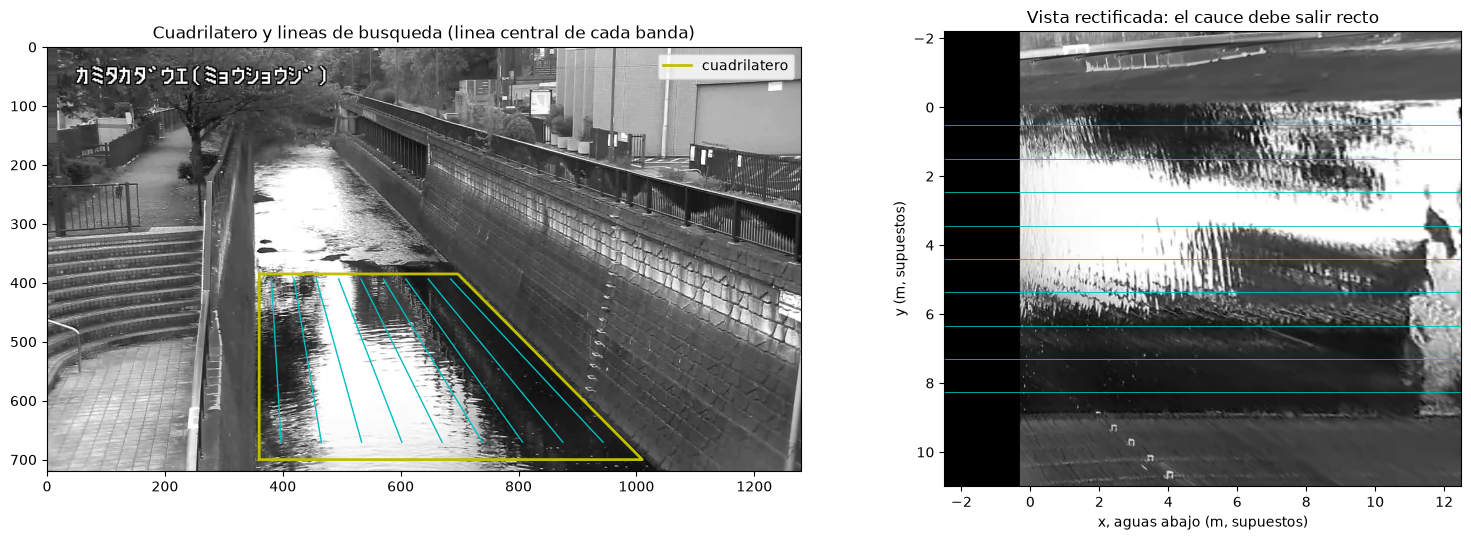

In [4]:
def mapa_lineas(centros, angulos_deg, ds, largo):
    """Coordenadas de muestreo de cada linea: mapx, mapy de forma (n_lineas, n_muestras).

    Cada linea tiene su centro (x, y) y su largo, en las unidades del plano.
    """
    centros = np.atleast_2d(np.asarray(centros, float))
    angs = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(centros),)))
    n_mu = int(largo / ds)
    # t recorre la linea centrada en su punto medio
    t = (np.arange(n_mu) - (n_mu - 1) / 2) * ds
    mapx = np.zeros((len(centros), n_mu), np.float32)
    mapy = np.zeros((len(centros), n_mu), np.float32)
    for i, ((cx, cy), a) in enumerate(zip(centros, angs)):
        mapx[i] = cx + t * np.cos(a)
        mapy[i] = cy + t * np.sin(a)
    return mapx, mapy


def mapa_banda(centros, angulos_deg, ds, largo, ancho, paso):
    """Una banda de lineas paralelas por estacion: (n_est * n_banda, n_muestras).

    Un angulo por estacion (o uno para todas).
    """
    c = np.asarray(centros, float)
    a = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(c),)))
    perp = np.column_stack([-np.sin(a), np.cos(a)])   # a traves de la linea, por estacion
    offsets = np.arange(-ancho / 2, ancho / 2 + 1e-9, paso)
    todos = (c[:, None, :] + offsets[None, :, None] * perp[:, None, :]).reshape(-1, 2)
    angs = np.repeat(np.degrees(a), len(offsets))
    return (*mapa_lineas(todos, angs, ds, largo), len(offsets))


def lineas(p, H, dt, alto, ancho):
    """[v9] Mapas de muestreo EN LA IMAGEN de las bandas de un preset, y lo que se deriva."""
    W = p["ancho_m"]
    ds = p["v_esperada"] * dt                                  # m por muestra: estelas a ~45 grados
    margen = p["margen_orilla"] * W
    ys = np.linspace(margen, W - margen, p["n_estaciones"])
    centros = np.column_stack([np.full(len(ys), p["largo_m"] * p["centro_linea"]), ys])
    paso = p["ancho_banda_m"] / (p["lineas_banda"] - 1)
    wx, wy, nb = mapa_banda(centros, 0.0, ds, p["largo_linea_m"], p["ancho_banda_m"], paso)
    q = a_imagen(H, np.stack([wx.ravel(), wy.ravel()], 1))
    mapx = q[:, 0].reshape(wx.shape).astype(np.float32)
    mapy = q[:, 1].reshape(wx.shape).astype(np.float32)
    px_muestra = float(np.median(np.hypot(np.diff(mapx, axis=1), np.diff(mapy, axis=1))))
    dentro = (mapx >= 0) & (mapx < ancho - 1) & (mapy >= 0) & (mapy < alto - 1)
    valido = dentro.reshape(len(ys), nb, -1).all(axis=1)
    return dict(ds=ds, ys=ys, nb=nb, mapx=mapx, mapy=mapy, valido=valido,
                cobertura=valido.mean(axis=1), sigma=max(0.7, px_muestra / 2), px_muestra=px_muestra)


G = lineas(P, H_MUNDO, DT, ALTO_PX, ANCHO_PX)
print(f"{len(G['ys'])} estaciones x {G['nb']} lineas de {G['mapx'].shape[1]} muestras; "
      f"DS = {G['ds'] * 1000:.1f} mm = {G['px_muestra']:.2f} px de imagen por muestra; "
      f"antialias sigma {G['sigma']:.2f} px")

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ax[0].imshow(frame)
c = np.array(P["cuadrilatero"] + [P["cuadrilatero"][0]])
ax[0].plot(c[:, 0], c[:, 1], "y-", lw=2, label="cuadrilatero")
for i in range(0, G["mapx"].shape[0], G["nb"]):
    ax[0].plot(G["mapx"][i + G["nb"] // 2], G["mapy"][i + G["nb"] // 2], "c-", lw=1)
ax[0].legend(); ax[0].set_title("Cuadrilatero y lineas de busqueda (linea central de cada banda)")
ax[1].imshow(cv2.cvtColor(vista, cv2.COLOR_BGR2RGB),
             extent=[-0.25 * P["largo_m"], 1.25 * P["largo_m"], 1.25 * P["ancho_m"], -0.25 * P["ancho_m"]])
for y in G["ys"]:
    ax[1].axhline(y, color="c", lw=0.6)
ax[1].set_xlabel("x, aguas abajo (m, supuestos)"); ax[1].set_ylabel("y (m, supuestos)")
ax[1].set_title("Vista rectificada: el cauce debe salir recto")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig2_geometria.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - El motor: una medida por segundo sobre los ultimos 10 s

El video se lee **fotograma a fotograma**, como llegaria del directo:

1. Si el fotograma no es nuevo (Parte 1), se descarta.
2. Si lo es: gris, (realce si el preset lo pide), antialias **solo sobre el recuadro de las lineas**,
   y `remap` de todas las lineas: una **fila** de la STI. Va a un buffer que guarda los ultimos
   `VENTANA_S` = 10 s.
3. Cada `PASO_MEDIDA_S` = 1 s, con el buffer lleno, se mide: la STI de cada estacion (banda
   normalizada y promediada, como desde la v6) y el tensor por bloques.

El cambio en el estimador: **quien vota**. En la v8 votaban los bloques mas brillantes, porque el
trazador eran detritos sueltos. Aqui el enemigo es otro: el codificador de YouTube **congela** parches
del agua (bloques "skip"), que en la STI son estelas verticales perfectas, de velocidad cero y
coherencia alta, **con el brillo normal del agua**: la seleccion por brillo no los distingue. Lo que
si los distingue es que **no cambian entre fotogramas reales**. La **actividad** de cada pixel de la
STI es `|I(t) - I(t-1)|`; un pixel es activo si su actividad (suavizada 5x5) llega a 0.5 niveles de
gris; un bloque vota si al menos la mitad de sus pixeles son activos, y dentro del bloque los
pixeles quietos no aportan gradiente. Es la generalizacion de la seleccion por senal de la v8.

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  El metodo, comun a todas las fuentes
# ---------------------------------------------------------------------------------------
# [v9] Ventana temporal de la STI y cada cuanto se mide.
VENTANA_S = 10.0
PASO_MEDIDA_S = 1.0
# Lado del bloque de STI sobre el que se resuelve un tensor.
LADO_BLOQUE = 64
# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.50
# Suavizado gaussiano previo a las derivadas, en pixeles de STI.
SIGMA_DERIVADA = 1.5
# [v9] Actividad: |I(t) - I(t-1)| entre fotogramas reales, en niveles de gris. El agua que el
# codificador congela da 0.00 exacto; el agua con textura, 0.7-5.6.
ACTIVIDAD_MIN = 0.5
# [v9] Fraccion de pixeles activos para que un bloque vote.
FRACCION_ACTIVA = 0.5
# ---------------------------------------------------------------------------------------


def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # fondo fijo de cada muestra (rayas verticales)
    a = a - a.mean(axis=1, keepdims=True)       # parpadeo de cada fotograma (rayas horizontales)
    d = a.std()
    return a / d if d > 0 else a


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA, peso=None):
    """Pendiente m (muestras/fila) y coherencia C de un trozo de STI.

    [v9] `peso` (0 o 1 por pixel) anula el gradiente de los pixeles quietos.
    """
    # Gaussiana opcional y diferencias centrales.
    g = cv2.GaussianBlur(bloque, (0, 0), sigma) if sigma > 0 else bloque
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It, Ix = np.gradient(g)
    if peso is not None:                                                             # [v9]
        It, Ix = It * peso, Ix * peso
    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0
    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # el autovector esta definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE, sigma=SIGMA_DERIVADA, valido=None,
              actividad=None):
    """Pendiente robusta de una STI, por bloques con solape: (m, coherencia mediana, bloques).

    `valido` (una por muestra) marca las muestras dentro del fotograma; los bloques que tocan
    alguna de fuera no cuentan.
    [v9] Con `actividad` (0/1 por pixel), solo votan los bloques con al menos FRACCION_ACTIVA
    de pixeles activos, y en ellos los pixeles quietos no aportan. Sustituye a la seleccion por
    brillo de la v8. Devuelve tambien cuantos bloques votaron.
    """
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            if valido is not None and not valido[x0:x0 + lado].all():
                continue
            peso = None
            if actividad is not None:                                                # [v9]
                peso = actividad[t0:t0 + lado, x0:x0 + lado]
                if peso.mean() < FRACCION_ACTIVA:
                    continue
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado], sigma, peso)
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    if not ms:
        return np.nan, 0.0, 0
    ms, cs = np.array(ms), np.array(cs)
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana, len(ms)
    # mediana ponderada por coherencia: los bloques nitidos pesan mas
    mm, cc = ms[usables], cs[usables]
    orden = np.argsort(mm)
    mm, cc = mm[orden], cc[orden]
    acumulado = np.cumsum(cc) / cc.sum()
    return float(mm[np.searchsorted(acumulado, 0.5)]), coh_mediana, len(ms)

### Control de calidad, en cada medida

Los criterios de la v8, evaluados en cada ventana:

- **Coherencia >= 0.60**, la de la v8.
- **Bloques activos >= 6** (nuevo): con el agua congelada por el codec no queda ninguno. Es el motivo
  `sin textura`.
- **Cobertura >= 0.50**: fraccion de la linea dentro del fotograma.
- Contraste, brillo y densidad de trazador siguen en el codigo; con el realce desactivado (la
  densidad se mide sobre el top-hat) y las camaras de dia, estan desactivados.

In [6]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterios de aceptacion
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima: la de la v8.
COH_MIN_ESTACION = 0.60
# [v9] Bloques activos minimos para que la medida cuente.
N_BLOQUES_MIN = 6
# Desactivado desde la v6.
CONTRASTE_MIN = 0.0
# Desactivado desde la v7.
BRILLO_MAX_AGUA = 255.0
# Fraccion minima de la linea dentro del fotograma.
COBERTURA_MIN = 0.50
# [v9] Desactivada: la densidad se cuenta sobre el top-hat, y aqui no hay realce.
DENSIDAD_MIN, DENSIDAD_MAX = 0.0, 1.0
UMBRAL_PARTICULA = 4.0
# ---------------------------------------------------------------------------------------


def medir_ventana(buffer, g):
    """[v9] Una medida sobre las filas del buffer: velocidad, coherencia, bloques y motivo."""
    n_est = len(g["ys"])
    B = np.stack(buffer).reshape(len(buffer), n_est, g["nb"], -1)     # (t, estacion, banda, muestra)
    salida = []
    for i in range(n_est):
        banda = B[:, i]
        # Cada linea de la banda se normaliza por separado y luego se promedian.
        sti = np.mean([preparar_sti(banda[:, b]) for b in range(g["nb"])], axis=0)
        crudo = banda.mean(axis=1)
        # Actividad entre fotogramas reales (cada fila ya lo es), suavizada 5x5.
        act = np.abs(np.diff(crudo, axis=0, prepend=crudo[:1]))
        act[0] = act[1]
        activa = (cv2.blur(act.astype(np.float32), (5, 5)) >= ACTIVIDAD_MIN).astype(np.float32)
        m, coh, n_bloques = medir_sti(sti, valido=g["valido"][i], actividad=activa)
        contraste = float(np.median(crudo.std(axis=0)))
        brillo = float(crudo.mean())
        densidad = float((banda.max(axis=1) > UMBRAL_PARTICULA).mean())
        motivos = [nombre for nombre, falla in [
            ("sin_textura", n_bloques < N_BLOQUES_MIN),
            ("coherencia", coh < COH_MIN_ESTACION),
            ("fuera_de_campo", g["cobertura"][i] < COBERTURA_MIN),
            ("estatica", contraste < CONTRASTE_MIN),
            ("orilla", brillo > BRILLO_MAX_AGUA),
            ("densidad", not DENSIDAD_MIN <= densidad <= DENSIDAD_MAX),
            ("sin_medida", not np.isfinite(m))] if falla]
        v = m * g["ds"] / g["dt"] if np.isfinite(m) else np.nan
        salida.append(dict(estacion=i, v=v, coherencia=coh, bloques=n_bloques,
                           aceptada=not motivos, motivos="+".join(motivos)))
    return salida


def medir_en_directo(p, registro_tiempos=None):
    """[v9] El bucle del programa en directo sobre un video: lee, filtra, apila y mide."""
    cap = cv2.VideoCapture(str(p["video"]))
    fps = cap.get(cv2.CAP_PROP_FPS)
    alto, ancho = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)), int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    k_real, _ = cadencia_real(p["video"])
    dt = k_real / fps
    H = geometria(p)
    g = lineas(p, H, dt, alto, ancho)
    g["dt"] = dt
    # Solo se suaviza el recuadro que tocan las lineas, con margen para el nucleo.
    mrg = int(np.ceil(4 * g["sigma"])) + 2
    x0, x1 = max(int(g["mapx"].min()) - mrg, 0), min(int(g["mapx"].max()) + mrg + 1, ancho)
    y0, y1 = max(int(g["mapy"].min()) - mrg, 0), min(int(g["mapy"].max()) + mrg + 1, alto)
    mx, my = g["mapx"] - x0, g["mapy"] - y0
    from collections import deque
    buffer = deque(maxlen=int(round(VENTANA_S / dt)))
    paso_filas = max(1, int(round(PASO_MEDIDA_S / dt)))
    previo, n, nuevas, medidas = None, 0, 0, []
    t_fotograma, t_medida = 0.0, 0.0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        c0 = time.perf_counter()
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
        nuevo = previo is None or diferencia(gris, previo) > UMBRAL_CAMBIO
        previo, n = gris, n + 1
        if nuevo:
            recorte = gris[y0:y1, x0:x1]
            if p["realce"] is not None:
                recorte = p["realce"](recorte)
            recorte = cv2.GaussianBlur(recorte.astype(np.float32), (0, 0), g["sigma"])
            buffer.append(cv2.remap(recorte, mx, my, cv2.INTER_LINEAR))
            nuevas += 1
        t_fotograma += time.perf_counter() - c0
        if len(buffer) == buffer.maxlen and nuevas >= paso_filas:
            nuevas = 0
            c0 = time.perf_counter()
            medidas.append((n / fps, medir_ventana(buffer, g)))
            t_medida += time.perf_counter() - c0
    cap.release()
    if registro_tiempos is not None:
        registro_tiempos.update(fotogramas=n, segundos_video=n / fps, ms_fotograma=1000 * t_fotograma / n,
                                ms_medida=1000 * t_medida / max(len(medidas), 1), medidas=len(medidas),
                                fps=fps, k_real=k_real)
    return g, medidas

In [7]:
import time

import pandas as pd

tiempos = {}
with benchmark.medir(f"Parte 4: motor en directo [{FUENTE}]", n_frames=N_TOTAL):    # [v9]
    G, medidas = medir_en_directo(P, tiempos)

# [v9] Una fila por estacion y medida, como el CSV del programa en directo.
serie = pd.DataFrame([dict(t_s=t, **r) for t, res in medidas for r in res])
serie.to_csv(SALIDA_SERIE, index=False)
print(f"{tiempos['medidas']} medidas (una por segundo, sobre los ultimos {VENTANA_S:.0f} s) "
      f"en {tiempos['segundos_video']:.0f} s de video")
por_estacion = serie.groupby("estacion").agg(
    aceptadas=("aceptada", "sum"), v_mediana=("v", lambda v: np.nan),
    coherencia=("coherencia", "median"), bloques=("bloques", "median"),
    motivo=("motivos", lambda m: m[m != ""].mode().iloc[0] if (m != "").any() else ""))
por_estacion["v_mediana"] = [serie[(serie.estacion == i) & serie.aceptada].v.median()
                             for i in por_estacion.index]
print(por_estacion.to_string(float_format=lambda x: f"{x:7.3f}"))

  [bench] Parte 4: motor en directo [myoshoji]: 5.1 s | CPU 13.0 s (2.6 nucleos) | RAM pico 280 MB
11 medidas (una por segundo, sobre los ultimos 10 s) en 20 s de video
          aceptadas  v_mediana  coherencia  bloques                             motivo
estacion                                                                              
0                11      0.472       0.681   30.000                                   
1                11      0.473       0.776   39.000                                   
2                10      0.464       0.634   24.000                         coherencia
3                11      0.496       0.806   24.000                                   
4                11      0.418       0.806   36.000                                   
5                11      0.470       0.781   37.000                                   
6                 0        NaN       0.485   39.000                         coherencia
7                 0        NaN       0.000    0.

---
## Parte 5 - La serie temporal y el perfil

Cada segundo da una medida por estacion; el resultado de un directo es una **serie**. La mediana de
la seccion en cada medida se calcula solo con las estaciones aceptadas en esa medida.

Las unidades son m/s **del rectangulo supuesto**: si el ancho real del cauce fuera 8.1 m (el limite
inferior de la ortofoto), todas las velocidades bajarian un 8 %.

  [bench] Parte 5: serie y perfil: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 165 MB
Velocidad superficial mediana: 0.472 m/s (escala SUPUESTA)
Mediana de seccion por medida: 0.466 a 0.484 m/s


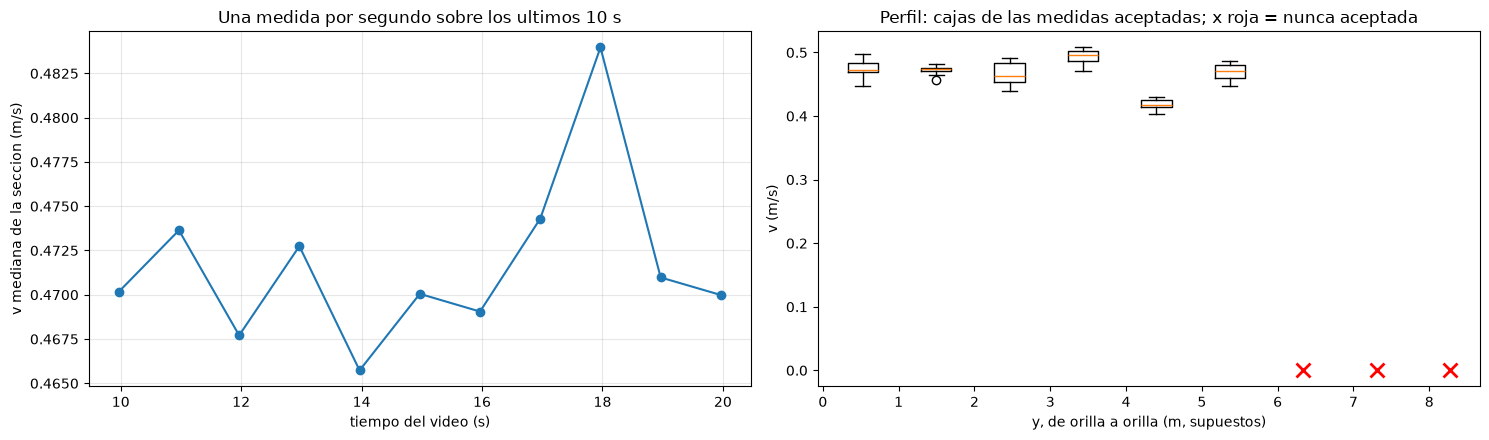

Configuracion congelada en: salidas\config.json


In [8]:
with benchmark.medir("Parte 5: serie y perfil"):
    V = np.array([[r["v"] if r["aceptada"] else np.nan for r in res] for _, res in medidas])
    t_medidas = np.array([t for t, _ in medidas])
    v_seccion = np.nanmedian(np.where(np.isfinite(V), V, np.nan), axis=1)
    v_mediana = float(np.nanmedian(V))

print(f"Velocidad superficial mediana: {v_mediana:.3f} m/s (escala SUPUESTA)")
print(f"Mediana de seccion por medida: {np.nanmin(v_seccion):.3f} a {np.nanmax(v_seccion):.3f} m/s")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(t_medidas, v_seccion, "o-", color="C0")
ax[0].set_xlabel("tiempo del video (s)"); ax[0].set_ylabel("v mediana de la seccion (m/s)")
ax[0].set_title("Una medida por segundo sobre los ultimos 10 s"); ax[0].grid(alpha=0.3)
ax[1].boxplot([V[np.isfinite(V[:, i]), i] for i in range(V.shape[1])], positions=G["ys"],
              widths=0.4, manage_ticks=False)
for i in range(V.shape[1]):
    if not np.isfinite(V[:, i]).any():
        ax[1].plot(G["ys"][i], 0, "rx", ms=10, mew=2)
ax[1].set_xlabel("y, de orilla a orilla (m, supuestos)"); ax[1].set_ylabel("v (m/s)")
ax[1].set_title("Perfil: cajas de las medidas aceptadas; x roja = nunca aceptada")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig3_serie_perfil.png", dpi=110, bbox_inches="tight")
plt.show()

import json
config = dict(fuente=FUENTE, preset={k: (str(v) if isinstance(v, Path) else v)
                                     for k, v in P.items() if k != "realce"},
              escala_verificada=False, fps=FPS, k_real=K_REAL, dt_real=DT,
              ventana_s=VENTANA_S, paso_medida_s=PASO_MEDIDA_S, lado_bloque=LADO_BLOQUE,
              coh_min_bloque=COH_MIN_BLOQUE, sigma_derivada=SIGMA_DERIVADA,
              actividad_min=ACTIVIDAD_MIN, fraccion_activa=FRACCION_ACTIVA,
              coh_min_estacion=COH_MIN_ESTACION, n_bloques_min=N_BLOQUES_MIN,
              cobertura_min=COBERTURA_MIN, v_mediana_ms=v_mediana)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2, default=str), encoding="utf-8")
print(f"Configuracion congelada en: {SALIDA_CONFIG}")

---
## Parte 6 - Recursos: el presupuesto del tiempo real

En un directo lo que importa no es cuanto tarda en total, sino si el motor **va por delante del
video**: cada fotograma tiene que procesarse en menos de lo que dura (33 ms a 30 fps), y cada medida
en menos de un segundo. El recuadro alrededor de las lineas es lo que hace barato el antialias: el
fotograma entero no se suaviza nunca.

In [9]:
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")
print(f"\n[{FUENTE}] {tiempos['ms_fotograma']:.1f} ms por fotograma (presupuesto {1000 / tiempos['fps']:.1f} ms), "
      f"{tiempos['ms_medida']:.0f} ms por medida (presupuesto {1000 * PASO_MEDIDA_S:.0f} ms)")
tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)
tabla_recursos

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 12
  cpu_nucleos_logicos: 16
  ram_total_gb: 42.7
  ram_disponible_gb: 21.1

[myoshoji] 1.4 ms por fotograma (presupuesto 33.3 ms), 131 ms por medida (presupuesto 1000 ms)


,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,Parte 4: motor en directo [myoshoji],5.06,13.05,2.58,279.7,-0.4,600.0,100.0
1,Parte 5: serie y perfil,0.00,0.00,0.00,164.7,0.0,NaN,0.0


---
## Parte 7 - Referencias

### Myoshoji: solo contexto

No hay aforo del directo. Lo que hay es indirecto: el caudal oficial del puente Ochiai, aguas abajo
(Q ~ 0.38 m3/s con 0.13 m de calado, 2005-2009), que da del orden de **0.4-0.6 m/s en superficie**
(`casos/09_directo_tokio/verificacion_nivel/`). Y el resultado del programa original sobre este mismo
video, que no es una referencia (es el mismo metodo con la cadencia fija y otro estimador).

### Sile Main Canal: el mismo motor, contra un aforo

La prueba que si es una validacion: pasar **este mismo motor**, con todos los parametros del metodo
tal como estan, por el video del Sile, el caso de la v2 y la v3, con la geometria de la v3 como
preset. Con dos diferencias deliberadas respecto a la v3: el video es el **original sin estabilizar**
(el programa en directo no estabiliza) y la medida es la de un directo, una por segundo sobre 10 s.
El caudal de cada medida se integra como en la v3 (relleno lineal, muros sin apoyo, `V_CORR` = 0.92,
calado 1.073 m), y se compara la mediana con el aforo.

**Esta es la ultima parte del notebook. No se vuelve atras a ajustar nada.**

Myoshoji: 0.472 m/s; orden de magnitud por el caudal oficial: 0.4-0.6 m/s; programa original 0.492 m/s (no es referencia)


  [bench] Parte 7: motor en directo [sile]: 94.3 s | CPU 198.8 s (2.1 nucleos) | RAM pico 759 MB

Sile, 13 medidas sobre el video sin estabilizar (98 ms por fotograma 4K):
  Q mediana 1.4698 m3/s (q05-q95 1.4325-1.5076); aforo 1.4362 -> +2.3 %
  v3 (estabilizado, el video entero de una vez): 1.4484265662462377 -> +0.9 %
 vertical     y_m  v_sup_v9  aceptada_en  v_media_v9  v_media_ADV  dif_pct
        1   0.152     0.676           10       0.622        0.630   -1.212
        2   0.305     0.812            8       0.747        0.797   -6.279
        3   0.457     0.872           13       0.802        0.813   -1.393
        4   0.610     0.904           13       0.832        0.812    2.412
        5   0.762     0.972           13       0.894        0.822    8.800
        6   0.914     0.986           13       0.907        0.852    6.529
        7   1.067     0.938           13       0.863        0.851    1.396
        8   1.219     0.944           13       0.868        0.846    2.637
   

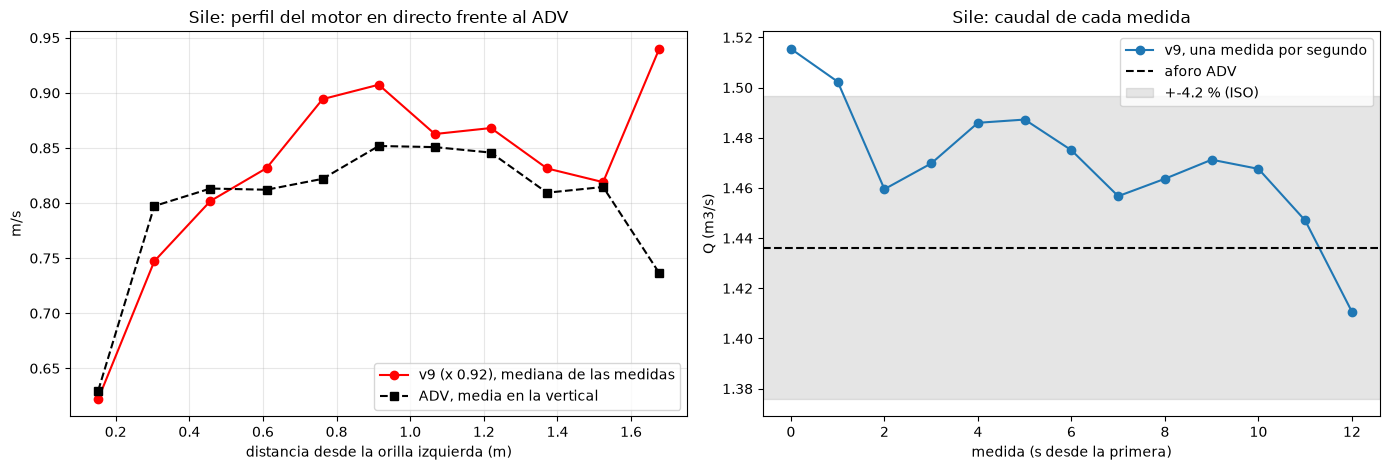

,concepto,valor,unidad
0,Myoshoji: velocidad superficial mediana,0.471697,"m/s, escala supuesta"
1,Myoshoji: estaciones con alguna medida aceptada,6.000000,de 9
2,Myoshoji: ms por fotograma,1.359362,ms
3,"Sile: caudal mediano (motor en directo, sin es...",1.469766,m3/s
4,Sile: diferencia con el aforo,2.337167,%


In [10]:
# [v9] Parte nueva.
V_PROGRAMA_ORIGINAL = 0.492   # m/s, casos/09_directo_tokio sobre este video (regresion myoshoji_dia20)
print(f"Myoshoji: {v_mediana:.3f} m/s; orden de magnitud por el caudal oficial: 0.4-0.6 m/s; "
      f"programa original {V_PROGRAMA_ORIGINAL:.3f} m/s (no es referencia)")

tiempos_sile = {}
with benchmark.medir("Parte 7: motor en directo [sile]", n_frames=672):
    G_sile, medidas_sile = medir_en_directo(FUENTES["sile"], tiempos_sile)
V_sile = np.array([[r["v"] if r["aceptada"] else np.nan for r in res] for _, res in medidas_sile])
ys_sile, W_sile = G_sile["ys"], FUENTES["sile"]["ancho_m"]
V_CORR, CALADO = 0.92, 1.073   # los de la v3; la seccion del CSV es de calado constante
Q_sile = []
for v in V_sile:
    ok = np.isfinite(v)
    if ok.sum() < 2:
        continue
    v = v.copy()
    v[~ok] = np.interp(ys_sile[~ok], ys_sile[ok], v[ok])      # muros sin apoyo, como la v3
    Q_sile.append(np.trapezoid(V_CORR * np.r_[0, v, 0] * np.r_[0, np.full(len(v), CALADO), 0],
                               np.r_[0, ys_sile, W_sile]))
Q_sile = np.array(Q_sile)

# ---------------------------------------------------------------------------------------
#  Datos de validacion del Sile. Primera vez que aparecen. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
Q_AFORO = 1.4362              # m3/s, FlowTracker (ADV) del 2020-08-17
V_ADV = np.array([0.6298, 0.7973, 0.8132, 0.8121, 0.8220, 0.8518, 0.8508, 0.8458, 0.8094,
                  0.8146, 0.7365])                            # m/s, verticales 1 a 11
# ---------------------------------------------------------------------------------------
# El resultado de la v3 sobre el video estabilizado, si se ha ejecutado.
ARCHIVO_V3 = Path("../v3_smc_stiv/salidas/caudal_resumen.csv")
Q_V3 = float(pd.read_csv(ARCHIVO_V3)["valor"].iloc[0]) if ARCHIVO_V3.exists() else np.nan
v_sile = np.nanmedian(V_sile, axis=0)
print(f"\nSile, {tiempos_sile['medidas']} medidas sobre el video sin estabilizar "
      f"({tiempos_sile['ms_fotograma']:.0f} ms por fotograma 4K):")
print(f"  Q mediana {np.median(Q_sile):.4f} m3/s (q05-q95 {np.percentile(Q_sile, 5):.4f}-"
      f"{np.percentile(Q_sile, 95):.4f}); aforo {Q_AFORO} -> {100 * (np.median(Q_sile) / Q_AFORO - 1):+.1f} %")
print(f"  v3 (estabilizado, el video entero de una vez): {Q_V3} -> {100 * (Q_V3 / Q_AFORO - 1):+.1f} %")
comp = pd.DataFrame({"vertical": np.arange(1, 12), "y_m": ys_sile, "v_sup_v9": v_sile,
                     "aceptada_en": np.isfinite(V_sile).sum(axis=0), "v_media_v9": V_CORR * v_sile,
                     "v_media_ADV": V_ADV})
comp["dif_pct"] = 100 * (comp.v_media_v9 / comp.v_media_ADV - 1)
print(comp.to_string(index=False, float_format=lambda x: f"{x:7.3f}"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(ys_sile, V_CORR * v_sile, "ro-", label="v9 (x 0.92), mediana de las medidas")
ax[0].plot(ys_sile, V_ADV, "ks--", label="ADV, media en la vertical")
ax[0].set_xlabel("distancia desde la orilla izquierda (m)"); ax[0].set_ylabel("m/s")
ax[0].set_title("Sile: perfil del motor en directo frente al ADV"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(np.arange(len(Q_sile)) * PASO_MEDIDA_S, Q_sile, "o-", label="v9, una medida por segundo")
ax[1].axhline(Q_AFORO, color="k", ls="--", label="aforo ADV")
ax[1].axhspan(Q_AFORO * 0.958, Q_AFORO * 1.042, color="gray", alpha=0.2, label="+-4.2 % (ISO)")
ax[1].set_xlabel("medida (s desde la primera)"); ax[1].set_ylabel("Q (m3/s)"); ax[1].legend()
ax[1].set_title("Sile: caudal de cada medida")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_regresion_sile.png", dpi=110, bbox_inches="tight")
plt.show()

resumen = pd.DataFrame([
    dict(concepto="Myoshoji: velocidad superficial mediana", valor=v_mediana, unidad="m/s, escala supuesta"),
    dict(concepto="Myoshoji: estaciones con alguna medida aceptada",
         valor=int(np.isfinite(V).any(axis=0).sum()), unidad=f"de {V.shape[1]}"),
    dict(concepto="Myoshoji: ms por fotograma", valor=tiempos["ms_fotograma"], unidad="ms"),
    dict(concepto="Sile: caudal mediano (motor en directo, sin estabilizar)", valor=float(np.median(Q_sile)), unidad="m3/s"),
    dict(concepto="Sile: diferencia con el aforo", valor=100 * (np.median(Q_sile) / Q_AFORO - 1), unidad="%"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
resumen

---
## Archivos generados

Todo queda en `salidas/`, sin tocar los datos de entrada.

In [11]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                    0.2 KiB
  config.json                               0.9 KiB
  fig1_fotograma.png                      301.3 KiB
  fig2_geometria.png                      574.3 KiB
  fig3_serie_perfil.png                    62.9 KiB
  fig4_regresion_sile.png                  79.9 KiB
  medidas_directo.csv                       6.9 KiB
  resumen.csv                               0.3 KiB


---
## Lectura del resultado

**Lo que aporta esta version al codigo**: el paso de un analisis a un **instrumento**. El metodo es el
mismo nucleo desde la v3 (una STI por linea, tensor de estructura por bloques, mediana ponderada por
coherencia), pero ahora se alimenta fotograma a fotograma, mide cada segundo, separa lo que depende de
la camara (los presets) de lo que es el metodo, y se defiende de dos artefactos que solo aparecen en un
directo: los fotogramas repetidos y el agua congelada por el codec.

**La regresion sobre el Sile cierra la serie**: el ultimo codigo, sin tocar un parametro del metodo,
vuelve al primer caso de STIV y lo mide sobre el video sin estabilizar, una vez por segundo.

## Limitaciones conocidas

1. **La escala de Myoshoji es un supuesto** (rectangulo de 10 x 8.8 m): las velocidades en m/s lo
   heredan.
2. **Las estaciones junto al muro derecho no se miden de dia**: el codec congela esa agua, que va
   lenta y en sombra (0 bloques activos). El programa original las recupera a veces con un segundo
   proceso de "motas" que aqui no se incluye.
3. **De noche esta camara no ve el agua que fluye** (destellos de farolas sobre ondulaciones casi
   fijas): el programa original tiene un modo noche (top-hat de 9 px, exclusion de deslumbramientos)
   y una cascada de escalas de tiempo para agua lenta, que este notebook no reproduce porque el video
   de prueba es de dia y a velocidad normal.
4. **Sin estabilizacion**: valida para camaras fijas; en el Sile la deriva del dron es un 0.4 % del
   desplazamiento por fila.
5. **Ventanas de 10 s**: suficientes para el agua de dia a ~0.5 m/s, cortas para agua mucho mas lenta.